# 05 · Modelos predictivos

**Proyecto:** videos en tendencia de YouTube en Estados Unidos
**Metodología:** CRISP-DM, etapas 4 (modelado) y 5 (evaluación)

Este notebook responde dos preguntas del enunciado:

- **¿Es posible predecir cuántas vistas o likes tendrá un video?** Se construyen modelos y se evalúan con datos que no vieron.
- **¿Qué combinación de atributos hace que un video sea tendencia?** El dataset solo contiene videos que ya llegaron a tendencia, así que no se puede modelar "llegar o no llegar". Se modela lo que sí se observa: **cuánto dura un video en la lista**.

## 1. Planteamiento

### 1.1 ¿Predecir con qué información?

Un modelo solo es útil si usa datos que existen en el momento de decidir. Se evalúan dos momentos:

| Momento | Información disponible | Decisión que apoya |
|---|---|---|
| **A. Antes de publicar** | Categoría, título, etiquetas, descripción, día y hora, historial previo del canal | Qué producir y con quién asociarse |
| **B. Primer día en tendencia** | Lo anterior más vistas, likes y comentarios de ese primer día | Si vale la pena impulsar un video que ya despegó |

Nunca se usan como predictores los likes o comentarios finales: se miden al mismo tiempo que las vistas finales, y usarlos daría un modelo muy preciso e inútil (notebook 01).

### 1.2 Cómo se evalúa

- **Corte temporal.** Se entrena con los videos que llegaron a tendencia antes del 1 de mayo de 2018 y se prueba con los que llegaron después. Así se imita el uso real: predecir el futuro con el pasado. Un reparto al azar dejaría que el modelo "viera" videos posteriores al que predice.
- **Variable objetivo en logaritmo**, por la asimetría de vistas y likes.
- **Métricas:** R² (proporción de la variación explicada) y **factor de error típico**: un factor de 2 significa que la predicción típica se desvía hasta el doble o la mitad del valor real.
- **Referencia sin modelo.** Cada modelo se compara con la mejor estimación que se podría hacer sin él. Un modelo solo aporta si la supera.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import make_column_transformer
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.append(str(Path.cwd().parent))
from src import prep
from src.data import FIGURES_DIR, PROCESSED_DIR
from src.viz import BLUE, COMPACT, INK_SECONDARY, PALETTE, set_style

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SEED = 42
CUT = "2018-05-01"

## 2. Variables predictoras

### 2.1 Historial del canal sin información del futuro

El notebook 03 mostró que el canal es el factor que más pesa. Para usarlo como predictor, el historial de cada video se calcula **solo con los videos del mismo canal que llegaron a tendencia antes que él**:

- `channel_prev_videos`: cuántos videos previos del canal llegaron a tendencia.
- `channel_prev_log_views`: vistas promedio (en logaritmo) de esos videos previos.
- `channel_prev_days`: días promedio en tendencia de esos videos previos.
- `channel_is_new`: el canal no tiene historial en el dataset.

Se excluyen los 101 videos antiguos que resurgieron: su fecha de publicación no guarda relación con su llegada a tendencia.

In [2]:
videos = pd.read_parquet(PROCESSED_DIR / "videos.parquet")
videos = prep.add_channel_history(prep.add_period(videos))
videos = videos[~videos["is_old_video"]].copy()

videos["is_late_period"] = (videos["period"] == prep.PERIODS[1]).astype(int)
videos["title_has_official"] = videos["title"].str.lower().str.contains("official")
videos["title_has_trailer"] = videos["title"].str.lower().str.contains("trailer")

print(f"Videos: {len(videos):,} · sin historial de canal: {videos['channel_is_new'].mean():.0%}")
videos.loc[videos["channel_title"] == "ESPN",
           ["first_trending_date", "title", "channel_prev_videos", "channel_prev_log_views", "log_views_last"]].head(4)

Videos: 6,246 · sin historial de canal: 34%


,first_trending_date,title,channel_prev_videos,channel_prev_log_views,log_views_last
3826,2017-11-14,Stephen A. Smith slams the Philadelphia 76ers ...,0,NaN,13.061
2127,2017-11-15,Stephen A. Smith: Jay Cutler is a 'disease' | ...,1,13.061,12.549
5853,2017-11-17,NBA Countdown debates if Ben Simmons is the be...,2,12.805,11.756
2429,2017-11-20,Is Chip Kelly interested in Gators job? | Spor...,3,12.455,10.641


In [3]:
LABELS = {
    "category": "Categoría",
    "publish_hour": "Hora de publicación",
    "publish_dow": "Día de publicación",
    "title_length": "Longitud del título",
    "title_upper_ratio": "Mayúsculas en el título",
    "title_has_exclamation": "Título con exclamación",
    "title_has_question": "Título con pregunta",
    "title_has_digit": "Título con números",
    "title_has_official": "Título con «official»",
    "title_has_trailer": "Título con «trailer»",
    "n_tags": "Número de etiquetas",
    "description_length": "Longitud de la descripción",
    "description_links": "Enlaces en la descripción",
    "channel_prev_videos": "Canal: videos previos en tendencia",
    "channel_prev_log_views": "Canal: vistas de sus videos previos",
    "channel_prev_days": "Canal: duración de sus videos previos",
    "channel_is_new": "Canal sin historial",
    "is_late_period": "Periodo (desde marzo de 2018)",
    "log_views_first": "Vistas el primer día",
    "log_likes_first": "Likes el primer día",
    "log_dislikes_first": "Dislikes el primer día",
    "log_comment_count_first": "Comentarios el primer día",
    "days_to_trending": "Días hasta llegar a tendencia",
}
BEFORE = [c for c in LABELS if c not in
          ("log_views_first", "log_likes_first", "log_dislikes_first", "log_comment_count_first", "days_to_trending")]
FIRST_DAY = list(LABELS)

numeric = [c for c in LABELS if c != "category"]
videos[numeric] = videos[numeric].astype(float)

train = videos[videos["first_trending_date"] < CUT]
test = videos[videos["first_trending_date"] >= CUT]
print(f"Entrenamiento: {len(train):,} videos (hasta abril de 2018) · Prueba: {len(test):,} videos (mayo y junio de 2018)")

Entrenamiento: 5,538 videos (hasta abril de 2018) · Prueba: 708 videos (mayo y junio de 2018)


## 3. Modelos candidatos

Se comparan tres modelos de complejidad creciente:

| Modelo | Por qué se incluye |
|---|---|
| **Regresión lineal Ridge** | Referencia simple e interpretable. Si un modelo complejo no la supera, no vale la pena. |
| **Random Forest** | Captura relaciones no lineales e interacciones (por ejemplo, que el efecto de la categoría dependa del canal). |
| **Gradient Boosting** | Suele ser el más preciso en datos tabulares como estos. |

Todos reciben las mismas variables: la categoría como indicadores, los faltantes imputados con la mediana (el historial de canales nuevos) y las variables numéricas estandarizadas.

In [4]:
def make_model(estimator, columns):
    numeric_cols = [c for c in columns if c != "category"]
    preprocess = make_column_transformer(
        (OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["category"]),
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_cols),
    )
    return make_pipeline(preprocess, estimator)


REGRESSORS = {
    "Ridge": lambda: RidgeCV(alphas=np.logspace(-2, 3, 20)),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED),
}


def score(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    return {"R²": r2_score(y_true, y_pred), "Error absoluto medio (log)": mae, "Factor de error típico": np.exp(mae)}


def evaluate(columns, target, baseline, train=train, test=test):
    """Entrena los tres modelos y los compara con una referencia sin modelo."""
    tr, te = train.dropna(subset=[target]), test.dropna(subset=[target])
    results = {"Referencia sin modelo": score(te[target], baseline(tr, te))}
    fitted = {}
    for name, build in REGRESSORS.items():
        fitted[name] = make_model(build(), columns).fit(tr[columns], tr[target])
        results[name] = score(te[target], fitted[name].predict(te[columns]))
    return pd.DataFrame(results).T, fitted


def recent_median(target):
    """Referencia antes de publicar: la mediana de los videos recientes del entrenamiento."""
    return lambda tr, te: np.full(len(te), tr.loc[tr["is_late_period"] == 1, target].median())


def first_day_growth(metric):
    """Referencia del primer día: el valor del primer día por el crecimiento típico reciente."""
    def predict(tr, te):
        recent = tr[tr["is_late_period"] == 1]
        growth = (recent[f"log_{metric}_last"] - recent[f"log_{metric}_first"]).median()
        return te[f"log_{metric}_first"] + growth
    return predict

## 4. Predicción de vistas

### 4.1 Momento A: antes de publicar

Referencia sin modelo: suponer que el video tendrá las vistas de un video típico reciente.

In [5]:
views_before, models_views_before = evaluate(BEFORE, "log_views_last", recent_median("log_views_last"))
views_before

,R²,Error absoluto medio (log),Factor de error típico
Referencia sin modelo,-0.279,1.014,2.758
Ridge,0.091,0.848,2.336
Random Forest,0.215,0.804,2.235
Gradient Boosting,0.209,0.803,2.232


### 4.2 Momento B: con los datos del primer día en tendencia

Referencia sin modelo: tomar las vistas del primer día y multiplicarlas por el crecimiento típico. Es una referencia exigente, porque las vistas finales incluyen las del primer día.

In [6]:
views_first, models_views_first = evaluate(FIRST_DAY, "log_views_last", first_day_growth("views"))
views_first

,R²,Error absoluto medio (log),Factor de error típico
Referencia sin modelo,0.726,0.424,1.529
Ridge,0.813,0.377,1.458
Random Forest,0.826,0.354,1.424
Gradient Boosting,0.855,0.327,1.387


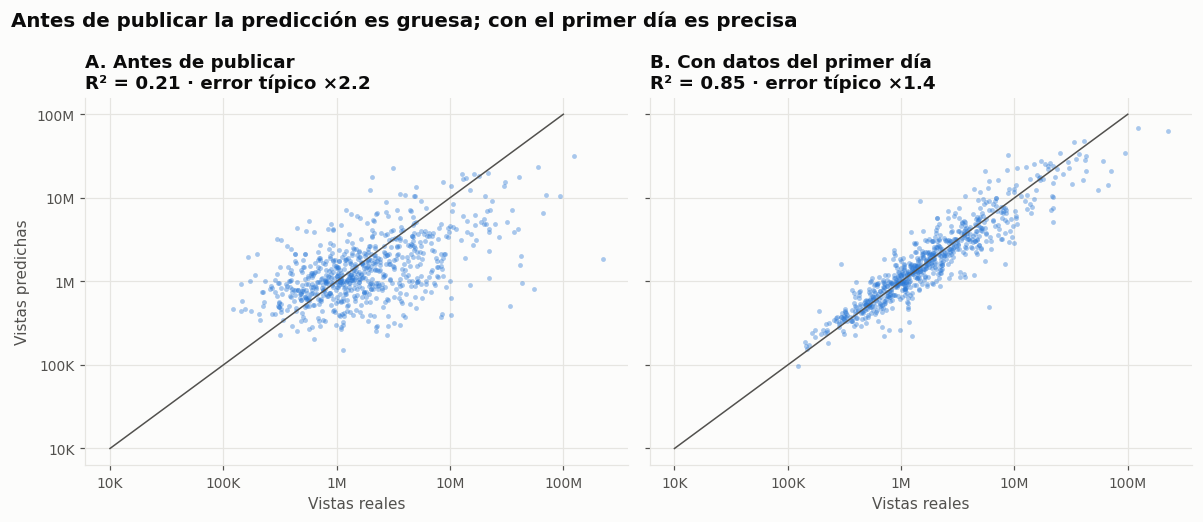

In [7]:
best_before = models_views_before["Gradient Boosting"]
best_first = models_views_first["Gradient Boosting"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
panels = [
    (best_before, BEFORE, views_before, "A. Antes de publicar"),
    (best_first, FIRST_DAY, views_first, "B. Con datos del primer día"),
]
ticks = np.log([1e4, 1e5, 1e6, 1e7, 1e8])
for ax, (model, columns, table, title) in zip(axes, panels):
    predicted = model.predict(test[columns])
    ax.scatter(test["log_views_last"], predicted, s=10, alpha=0.4, color=BLUE, linewidths=0)
    ax.plot([ticks[0], ticks[-1]], [ticks[0], ticks[-1]], color=INK_SECONDARY, linewidth=1)
    row = table.loc["Gradient Boosting"]
    ax.set_title(f"{title}\nR² = {row['R²']:.2f} · error típico ×{row['Factor de error típico']:.1f}")
    ax.set_xlabel("Vistas reales")
    ax.set_xticks(ticks, ["10K", "100K", "1M", "10M", "100M"])
    ax.set_yticks(ticks, ["10K", "100K", "1M", "10M", "100M"])
    ax.grid(axis="x")
axes[0].set_ylabel("Vistas predichas")
fig.suptitle("Antes de publicar la predicción es gruesa; con el primer día es precisa",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_prediccion_vistas.png")
plt.show()

### 4.3 ¿De qué depende la predicción?

Se usa la **importancia por permutación** sobre los datos de prueba: se desordena una variable y se mide cuánto empeora el modelo. Mide cuánto depende el modelo de cada variable, no un efecto causal.

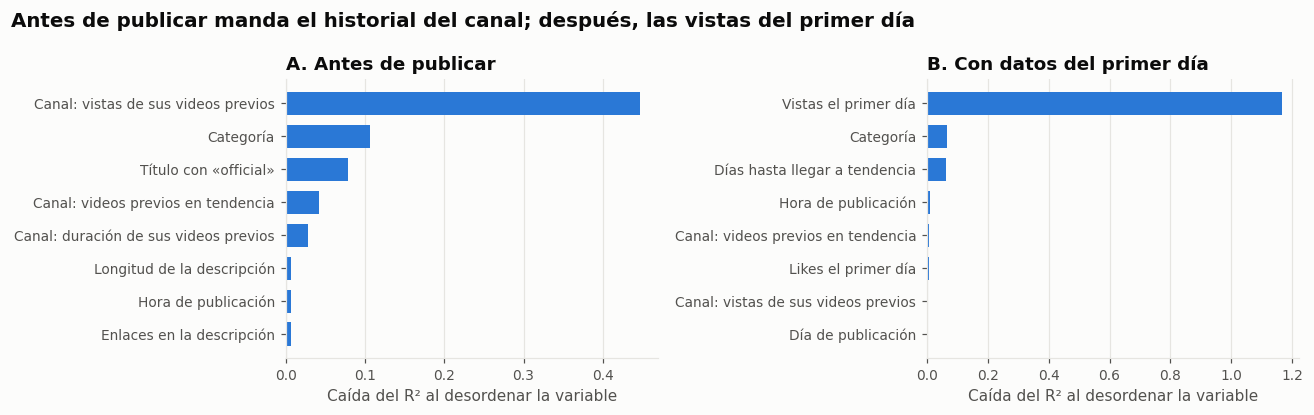

In [8]:
def importance(model, columns, target, data=test, scoring="r2", top=8):
    data = data.dropna(subset=[target])
    result = permutation_importance(model, data[columns], data[target], scoring=scoring,
                                    n_repeats=10, random_state=SEED)
    return (pd.Series(result.importances_mean, index=[LABELS[c] for c in columns])
            .sort_values(ascending=False).head(top))


imp_before = importance(best_before, BEFORE, "log_views_last")
imp_first = importance(best_first, FIRST_DAY, "log_views_last")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, series, title in [(axes[0], imp_before, "A. Antes de publicar"),
                          (axes[1], imp_first, "B. Con datos del primer día")]:
    series = series.iloc[::-1]
    ax.barh(series.index, series.values, color=BLUE, height=0.7)
    ax.set_title(title)
    ax.set_xlabel("Caída del R² al desordenar la variable")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
fig.suptitle("Antes de publicar manda el historial del canal; después, las vistas del primer día",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_importancia_vistas.png")
plt.show()

In [9]:
predicted = pd.Series(best_before.predict(test[BEFORE]), index=test.index)
by_history = pd.DataFrame({
    "videos": test.groupby("channel_is_new").size(),
    "R²": test.groupby("channel_is_new").apply(lambda g: r2_score(g["log_views_last"], predicted[g.index])),
    "Factor de error típico": test.groupby("channel_is_new").apply(
        lambda g: np.exp(mean_absolute_error(g["log_views_last"], predicted[g.index]))),
}).rename(index={0.0: "Canal con historial", 1.0: "Canal sin historial"})
by_history

,videos,R²,Factor de error típico
channel_is_new,,,
Canal con historial,613,0.297,2.097
Canal sin historial,95,-0.327,3.342


**Lectura:**

- **Antes de publicar, la predicción es gruesa.** El mejor modelo explica cerca del 21% de la variación y se equivoca típicamente por un factor de 2,2: si predice 1 millón de vistas, lo normal es que el video termine entre 450 mil y 2,2 millones. Mejora la referencia sin modelo (factor de 2,8), pero no alcanza para estimar el alcance de un video concreto. Sirve para **ordenar** propuestas de mayor a menor potencial.
- **Casi todo lo que el modelo sabe viene del canal.** La variable que más pesa es cuántas vistas tuvieron los videos anteriores del canal; después, la categoría. El título, las etiquetas y la hora aportan muy poco.
- **Para un canal sin historial, el modelo no sirve** (R² negativo, error por un factor de 3,3). Es la situación de un canal de marca recién creado: no hay forma de anticipar su resultado con estos datos.
- **Con los datos del primer día en tendencia, la predicción es precisa.** El Gradient Boosting explica el 85% de la variación con un error típico de un factor de 1,4, frente a 1,5 de la regla simple "vistas del primer día por el crecimiento habitual". La mejora sobre esa regla es real pero moderada: el primer día ya dice casi todo.
- **Modelo elegido: Gradient Boosting.** Es el mejor o empata como mejor en los dos momentos. La regresión lineal queda claramente atrás antes de publicar (R² de 0,09 frente a 0,21), señal de que las relaciones no son lineales.

## 5. Predicción de likes

Mismo procedimiento, con los likes finales como objetivo. Se excluyen los videos con valoraciones desactivadas.

In [10]:
likes_before, models_likes_before = evaluate(BEFORE, "log_likes_last", recent_median("log_likes_last"))
likes_first, models_likes_first = evaluate(FIRST_DAY, "log_likes_last", first_day_growth("likes"))

display(likes_before.style.set_caption("Likes · A. Antes de publicar").format("{:.3f}"))
display(likes_first.style.set_caption("Likes · B. Con datos del primer día").format("{:.3f}"))
importance(models_likes_before["Gradient Boosting"], BEFORE, "log_likes_last").to_frame("Caída del R² (antes de publicar)")

,R²,Error absoluto medio (log),Factor de error típico
Referencia sin modelo,-0.147,1.233,3.431
Ridge,0.199,0.979,2.661
Random Forest,0.303,0.898,2.454
Gradient Boosting,0.350,0.874,2.396


,R²,Error absoluto medio (log),Factor de error típico
Referencia sin modelo,0.935,0.249,1.282
Ridge,0.947,0.243,1.275
Random Forest,0.945,0.232,1.261
Gradient Boosting,0.951,0.219,1.245


,Caída del R² (antes de publicar)
Canal: vistas de sus videos previos,0.405
Categoría,0.188
Canal: videos previos en tendencia,0.046
Longitud del título,0.026
Hora de publicación,0.025
Título con «official»,0.019
Número de etiquetas,0.019
Enlaces en la descripción,0.010


**Lectura:**

- Los likes se predicen algo mejor que las vistas antes de publicar (R² de 0,35), porque dependen más de la categoría: como se vio en el notebook 03, hay categorías con audiencias que valoran mucho (Música, Howto & Style) y otras que casi no (Noticias, Deportes). Aun así el error típico es de un factor de 2,4.
- Con los datos del primer día, los likes finales se predicen con un R² de 0,95. Aquí el modelo casi no mejora la regla simple (0,94): los likes del primer día bastan.

## 6. ¿Los resultados dependen de la fecha de corte?

Un solo corte puede dar un resultado afortunado. Se repite la evaluación del Gradient Boosting con cuatro cortes: se entrena con todo lo anterior a la fecha y se prueba con los 30 días siguientes.

In [11]:
rows = []
for cut in ["2018-02-01", "2018-03-01", "2018-04-01", "2018-05-01"]:
    start = pd.Timestamp(cut)
    tr = videos[videos["first_trending_date"] < start]
    te = videos[(videos["first_trending_date"] >= start)
                & (videos["first_trending_date"] < start + pd.Timedelta(days=30))]
    row = {"Corte": start.strftime("%d-%m-%Y"), "Entrenamiento": len(tr), "Prueba": len(te)}
    for label, columns in [("A. Antes de publicar", BEFORE), ("B. Primer día", FIRST_DAY)]:
        model = make_model(REGRESSORS["Gradient Boosting"](), columns).fit(tr[columns], tr["log_views_last"])
        row[f"R² {label}"] = r2_score(te["log_views_last"], model.predict(te[columns]))
    rows.append(row)
pd.DataFrame(rows).set_index("Corte")

,Entrenamiento,Prueba,R² A. Antes de publicar,R² B. Primer día
Corte,,,,
01-02-2018,3259,1127,0.089,0.874
01-03-2018,4314,675,0.004,0.856
01-04-2018,5006,532,0.158,0.878
01-05-2018,5538,523,0.221,0.875


- **Con datos del primer día, el resultado es estable:** R² entre 0,86 y 0,88 en los cuatro cortes.
- **Antes de publicar, el resultado es inestable:** el R² va de 0,00 a 0,22. El peor caso es el corte de marzo de 2018, justo cuando cambia la lista de tendencias: un modelo entrenado con las reglas anteriores no sirve para las nuevas. La cifra de 0,21 del corte principal es el mejor caso, no el esperado.
- Consecuencia práctica: un modelo de este tipo tendría que **reentrenarse con frecuencia** y vigilarse, porque la plataforma cambia.

## 7. ¿Qué hace que un video dure en tendencia?

**Objetivo:** clasificar si un video durará **más que la mediana de su periodo** (más de 5 días hasta febrero, más de 9 desde marzo). Definirlo así evita que el modelo aprenda solo el cambio de marzo.

Se usan únicamente los videos con duración completa (se excluye el 16,5% marcado en el notebook 02). Se comparan una regresión logística, como referencia interpretable, y un Gradient Boosting. La métrica es el **AUC**: 0,5 equivale a adivinar y 1 a acertar siempre.

In [12]:
complete = videos[~videos["duration_incomplete"]].copy()
threshold = complete.groupby("period", observed=True)["days_trending"].transform("median")
complete["long_trending"] = (complete["days_trending"] > threshold).astype(int)

d_train = complete[complete["first_trending_date"] < CUT]
d_test = complete[complete["first_trending_date"] >= CUT]
print(f"Entrenamiento: {len(d_train):,} · Prueba: {len(d_test):,} · "
      f"duran más que la mediana: {complete['long_trending'].mean():.0%}")

CLASSIFIERS = {
    "Regresión logística": lambda: LogisticRegression(max_iter=2000, C=0.5),
    "Gradient Boosting": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED),
}
rows, duration_models = {}, {}
for moment, columns in [("A. Antes de publicar", BEFORE), ("B. Primer día", FIRST_DAY)]:
    for name, build in CLASSIFIERS.items():
        model = make_model(build(), columns).fit(d_train[columns], d_train["long_trending"])
        duration_models[(moment, name)] = model
        rows.setdefault(name, {})[f"AUC {moment}"] = roc_auc_score(
            d_test["long_trending"], model.predict_proba(d_test[columns])[:, 1])
pd.DataFrame(rows).T

Entrenamiento: 4,715 · Prueba: 508 · duran más que la mediana: 48%


,AUC A. Antes de publicar,AUC B. Primer día
Regresión logística,0.723,0.732
Gradient Boosting,0.742,0.762


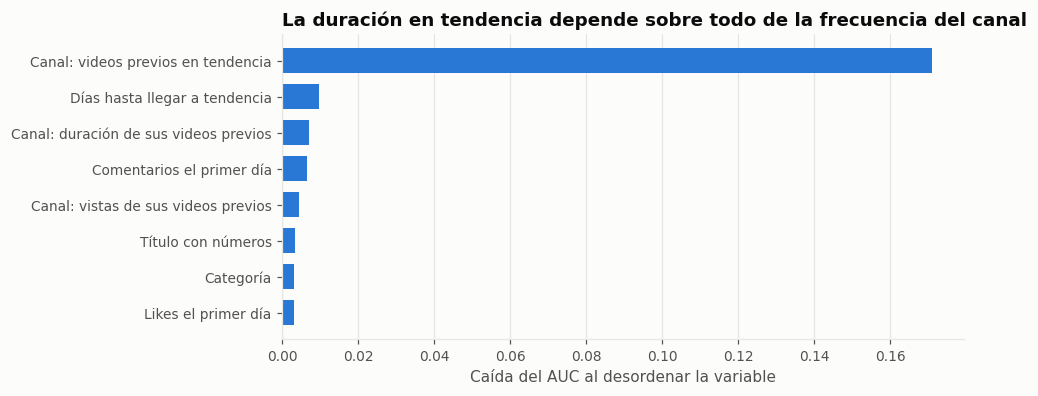

In [13]:
imp_duration = importance(duration_models[("B. Primer día", "Gradient Boosting")], FIRST_DAY,
                          "long_trending", data=d_test, scoring="roc_auc")

fig, ax = plt.subplots(figsize=(8, 3.6))
series = imp_duration.iloc[::-1]
ax.barh(series.index, series.values, color=BLUE, height=0.7)
ax.set_title("La duración en tendencia depende sobre todo de la frecuencia del canal")
ax.set_xlabel("Caída del AUC al desordenar la variable")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "05_importancia_duracion.png")
plt.show()

In [14]:
bins = pd.cut(complete["channel_prev_videos"], [-1, 0, 2, 5, 15, 100],
              labels=["Sin historial", "1 a 2", "3 a 5", "6 a 15", "Más de 15"])
by_frequency = complete.groupby(bins, observed=True).agg(
    videos=("video_id", "count"),
    pct_duran_mas=("long_trending", lambda s: s.mean() * 100),
    dias_en_tendencia=("days_trending", "mean"),
    vistas_mediana=("views_last", "median"),
)
by_frequency.index.name = "Videos previos del canal en tendencia"

by_category = complete.groupby("category").agg(
    videos=("video_id", "count"), pct_duran_mas=("long_trending", lambda s: s.mean() * 100),
).query("videos >= 100").sort_values("pct_duran_mas", ascending=False)

display(by_frequency.style.format({"pct_duran_mas": "{:.0f}%", "dias_en_tendencia": "{:.1f}", "vistas_mediana": "{:,.0f}"}))
display(by_category.style.format({"pct_duran_mas": "{:.0f}%"}))

,videos,pct_duran_mas,dias_en_tendencia,vistas_mediana
Videos previos del canal en tendencia,,,,
Sin historial,1680,53%,6.3,"300,206"
1 a 2,1141,60%,7.0,"502,681"
3 a 5,745,54%,7.3,"597,124"
6 a 15,925,43%,6.6,"579,189"
Más de 15,732,18%,4.6,"649,012"


,videos,pct_duran_mas
category,,
Music,613,66%
Film & Animation,248,60%
Education,198,55%
Howto & Style,491,51%
Pets & Animals,114,49%
People & Blogs,413,49%
Comedy,465,48%
Science & Technology,311,45%
Entertainment,1348,43%


**Lectura:**

- **Se puede anticipar razonablemente si un video durará** (AUC de 0,74 antes de publicar y 0,76 con el primer día). No es una predicción fina, pero es bastante mejor que adivinar.
- **El factor dominante es la frecuencia con que el canal entra a tendencia, y juega en contra.** Solo el 18% de los videos de canales con más de 15 apariciones previas dura más que la mediana, frente al 53–60% de los canales con poca o ninguna historia. Los canales que publican a diario (programas de televisión, deportes, noticias) entran siempre pero cada video es reemplazado por el siguiente.
- **La categoría también cuenta:** Música (66%) y Film & Animation (60%) son las que más duran; Sports (31%) y News & Politics (37%) las que menos. El contenido de actualidad caduca; el contenido que se puede ver en cualquier momento permanece.
- Los atributos del título, las etiquetas y el momento de publicación prácticamente no influyen en la duración.

**Respuesta a "qué hace tendencia a un video", con lo que los datos permiten:** no hay una combinación de título, etiquetas y horario que lo logre. Lo que distingue a los videos que más alcance y permanencia tienen es **quién los publica** (un canal con audiencia previa) y **qué tipo de contenido es** (atemporal, no de actualidad).

## 8. Conclusiones

| Pregunta | Respuesta |
|---|---|
| ¿Se pueden predecir las vistas y los likes **antes de publicar**? | Solo de forma gruesa: error típico de un factor de 2,2 en vistas y 2,4 en likes, y nada para canales sin historial. Útil para ordenar opciones, no para prometer cifras. |
| ¿Y **una vez el video llega a tendencia**? | Sí, con precisión: R² de 0,85 en vistas y 0,95 en likes usando los datos del primer día. |
| ¿Qué atributos hacen que un video dure en tendencia? | El tipo de canal y de contenido. Título, etiquetas y horario casi no cuentan. |

**Modelo elegido:** Gradient Boosting, por ser el más preciso en los tres problemas y manejar relaciones no lineales. La regresión Ridge y la logística se usaron como referencia interpretable.

**Qué significa para la empresa:**

- **El canal es el activo.** La audiencia previa explica más que cualquier decisión sobre un video individual. Mientras el canal propio no tenga historial, su resultado es impredecible; asociarse con canales establecidos reduce esa incertidumbre.
- **No hay fórmula de título u horario.** Optimizar esos detalles tiene un efecto marginal.
- **La señal temprana es confiable.** El desempeño del primer día en tendencia permite proyectar el resultado final y decidir a tiempo qué videos impulsar con pauta o difusión.
- **El contenido atemporal rinde más tiempo** que el de actualidad.

**Limitaciones:**

- **Sesgo de selección.** Todos los videos del dataset llegaron a tendencia. Los modelos predicen cuántas vistas tendrá un video *dado que llega*, no si llegará. Para eso harían falta datos de videos que no llegaron.
- **El historial del canal es parcial:** solo cuenta apariciones en tendencia dentro del periodo. No se conocen los suscriptores, que serían mejor predictor.
- **Las vistas finales están truncadas** para los videos que seguían en tendencia el último día del dataset.
- **Siete meses y un cambio de reglas en medio.** El modelo "antes de publicar" es sensible a ese cambio; habría que reentrenarlo y monitorearlo.
- **Asociación, no causalidad.** Que los canales con historial tengan más vistas no prueba que un sponsor traslade esa audiencia a la marca; eso se comprobaría con un experimento.